# **Details:**

**Name:** Vinit Jadhav

**PRN:** 202401040163

**Div:** A

**Roll No.:** 38


# **Title**

Performance Evaluation of Regression Models and Gradient Descent Optimization

# **Aim**

To develop regression models for a real-world application, evaluate their performance using appropriate regression metrics, and implement Gradient Descent optimization for Linear Regression to study its convergence and performance.

# **Experiment Objectives**

- To understand the concept and applications of regression.
- To use a real-world dataset for a regression problem.
- To prepare training and testing datasets.
- To implement multiple regression models and compare their performance.
- To evaluate models using MAE, MSE, RMSE, and R² score.
- To implement Linear Regression using Gradient Descent from scratch.
- To analyze the effect of learning rate and number of iterations on convergence.
- To compare the Gradient Descent model with the standard Linear Regression model.

# **Experiment Outcome**

- Loaded and explored a real-world medical dataset.
- Built multiple regression models to predict a continuous target value.
- Evaluated the models using four commonly used regression metrics.
- Compared model performance on unseen test data.
- Implemented Gradient Descent for Linear Regression without using a model-training library.
- Visualized the cost reduction during Gradient Descent.
- Studied how the learning rate affects convergence.
- Identified the limitations and responsible-use considerations of predictive models.

# **Theory**

### Regression

Regression is a supervised machine learning technique used to predict a continuous numerical value from input features. Examples include predicting house prices, sales, temperature, and medical measurements.

### Linear Regression

Linear Regression models the relationship between input features and a continuous target. It estimates coefficients and an intercept to minimize prediction error.

### Regression Evaluation Metrics

- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted values. Lower is better.
- **MSE (Mean Squared Error):** Average squared prediction error. Lower is better and larger errors receive more penalty.
- **RMSE (Root Mean Squared Error):** Square root of MSE. It is expressed in the same unit as the target. Lower is better.
- **R² Score:** Measures the proportion of target variation explained by the model. A value closer to 1 generally indicates a better fit; it can be negative when the model performs worse than predicting the test-set mean.

### Gradient Descent

Gradient Descent is an optimization algorithm that updates model parameters in the direction that reduces the loss function. For Linear Regression, the parameters are updated repeatedly using the gradients of Mean Squared Error. The learning rate controls the size of each update.

### Dataset Used

The experiment uses the Diabetes dataset available in scikit-learn. It contains baseline medical measurements and a quantitative measure of disease progression one year later. The task is a regression exercise, not a medical diagnosis tool. Features are standardized before Gradient Descent so that their scales are more comparable.

# **Problem Statement**

Build regression models to estimate the quantitative measure of disease progression one year after baseline using the Diabetes dataset.

The following models are developed and compared:

1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor

Evaluate the models using MAE, MSE, RMSE, and R² score. Then implement Linear Regression using Gradient Descent from scratch and analyze how its cost changes with iterations and different learning rates.

# **1. Import Required Libraries**

Import the Python libraries required for data handling, visualization, model building, preprocessing, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


# **2. Load and Understand the Dataset**

Load the Diabetes dataset from scikit-learn. Display the number of records, feature names, first few rows, and basic statistical information.

In [2]:
diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("\nFeature names:")
print(list(X.columns))
print("\nFirst five records:")
display(df.head())
print("\nDataset information:")
print(df.describe().round(2))

Dataset shape: (442, 11)

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First five records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Dataset information:
          age     sex     bmi      bp  ...      s4      s5      s6  target
count  442.00  442.00  442.00  442.00  ...  442.00  442.00  442.00  442.00
mean    -0.00    0.00   -0.00   -0.00  ...   -0.00    0.00    0.00  152.13
std      0.05    0.05    0.05    0.05  ...    0.05    0.05    0.05   77.09
min     -0.11   -0.04   -0.09   -0.11  ...   -0.08   -0.13   -0.14   25.00
25%     -0.04   -0.04   -0.03   -0.04  ...   -0.04   -0.03   -0.03   87.00
50%      0.01   -0.04   -0.01   -0.01  ...   -0.00   -0.00   -0.00  140.50
75%      0.04    0.05    0.03    0.04  ...    0.03    0.03    0.03  211.50
max      0.11    0.05    0.17    0.13  ...    0.19    0.13    0.14  346.00

[8 rows x 11 columns]


# **3. Exploratory Data Analysis**

Check missing values and visualize the target distribution and feature relationships. These plots help understand the data before model training.

Missing values in each column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


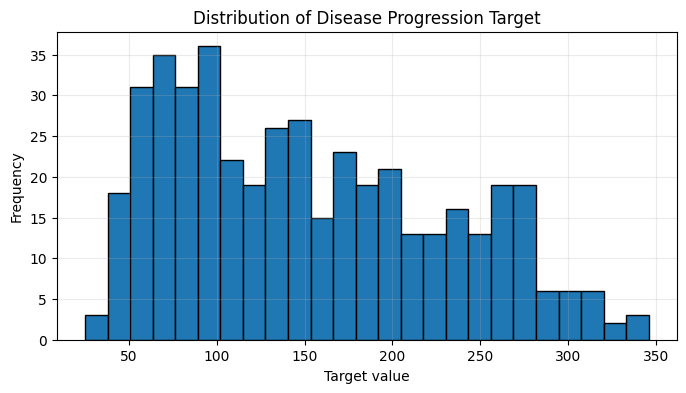

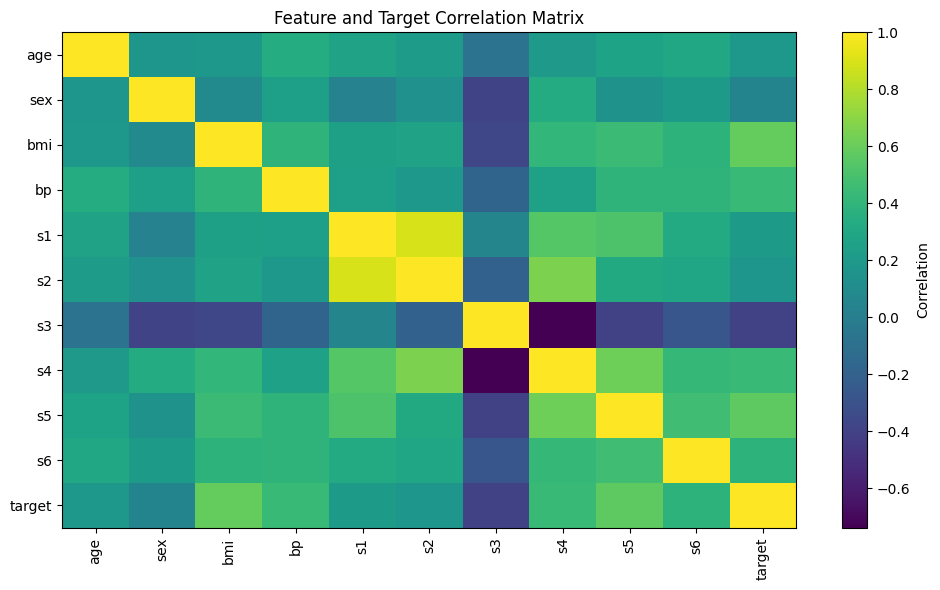

In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

plt.figure(figsize=(8, 4))
plt.hist(y, bins=25, edgecolor="black")
plt.title("Distribution of Disease Progression Target")
plt.xlabel("Target value")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 6))
correlation = df.corr(numeric_only=True)
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Feature and Target Correlation Matrix")
plt.tight_layout()
plt.show()

# **4. Data Preprocessing**

Separate the input features and target variable. Split the dataset into training and testing sets. The test set is kept separate and is used only for final evaluation.

For the Gradient Descent implementation, feature scaling is performed using the training data only. This avoids data leakage from the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape :", X_test.shape)
print("Training target shape :", y_train.shape)
print("Testing target shape  :", y_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")

Training feature shape: (353, 10)
Testing feature shape : (89, 10)
Training target shape : (353,)
Testing target shape  : (89,)

Feature scaling completed.


# **5. Develop Regression Models**

Train five regression algorithms. Pipelines are used for Linear Regression and Ridge Regression so that scaling is learned only from the training data. Tree-based models are trained on the original feature values.

In [5]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=4, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(by="RMSE").reset_index(drop=True)

print("Regression models trained successfully.")
display(results_df.round(3))

Regression models trained successfully.


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,42.703,2774.634,52.675,0.476
1,Random Forest,43.063,2808.904,52.999,0.470
2,Ridge Regression,42.812,2892.015,53.777,0.454
3,Linear Regression,42.794,2900.194,53.853,0.453
4,Decision Tree,47.045,3568.965,59.741,0.326


# **6. Compare Model Performance**

Compare the models using RMSE and R² score. RMSE measures prediction error in the target's unit, while R² describes the proportion of variance explained by the model. No single metric should be used in isolation.

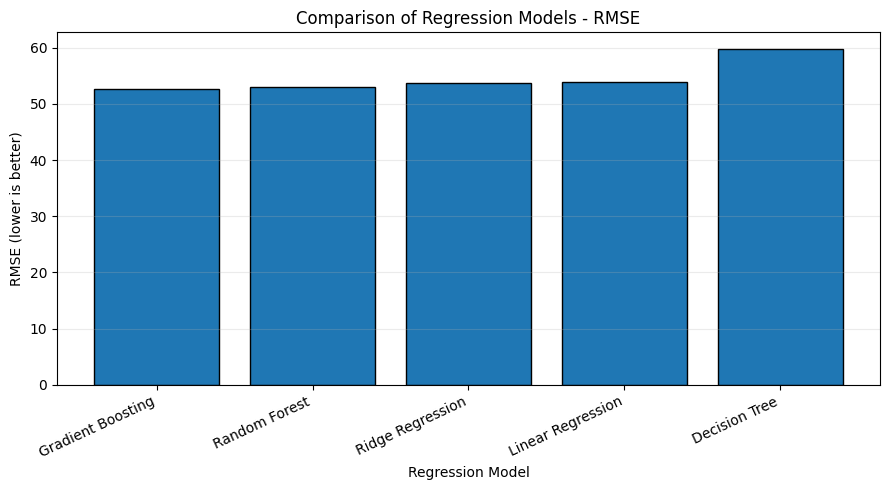

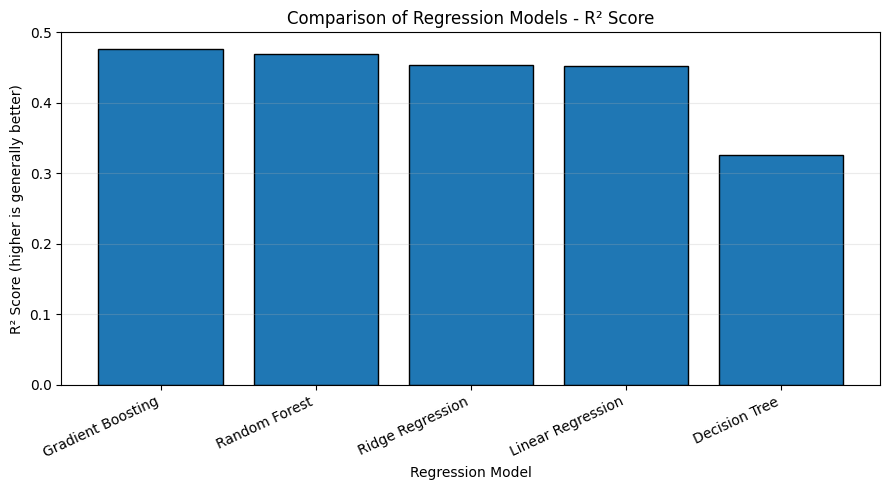

Model with the lowest test RMSE: Gradient Boosting
Its test RMSE: 52.675


In [6]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"], edgecolor="black")
plt.title("Comparison of Regression Models - RMSE")
plt.xlabel("Regression Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2 Score"], edgecolor="black")
plt.title("Comparison of Regression Models - R² Score")
plt.xlabel("Regression Model")
plt.ylabel("R² Score (higher is generally better)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print("Model with the lowest test RMSE:", best_model_name)
print("Its test RMSE:", round(results_df.iloc[0]["RMSE"], 3))

# **7. Actual vs Predicted Values**

Use the best model according to test RMSE to visualize actual target values against predicted values. Points closer to the diagonal line represent more accurate predictions.

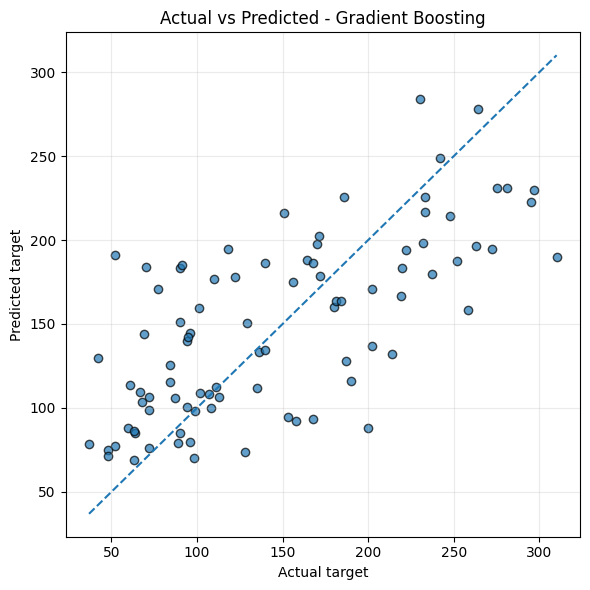

,Actual Value,Predicted Value
0,219.0,166.51
1,70.0,183.93
2,202.0,171.04
3,230.0,284.03
4,111.0,112.53
5,84.0,115.47
6,242.0,249.09
7,272.0,194.51
8,94.0,139.97
9,96.0,144.72


In [7]:
best_predictions = predictions[best_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.7, edgecolor="black")
line_min = min(float(y_test.min()), float(best_predictions.min()))
line_max = max(float(y_test.max()), float(best_predictions.max()))
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Actual Value": y_test.to_numpy()[:10],
    "Predicted Value": best_predictions[:10]
})
display(comparison.round(2))

# **8. Implement Linear Regression Using Gradient Descent**

Gradient Descent is implemented from scratch. The cost function is Mean Squared Error divided by two:

\[
J(w,b) = \frac{1}{2m}\sum_{i=1}^{m}(\hat{y}_i-y_i)^2
\]

The parameter updates are:

\[
w := w - \alpha \frac{1}{m}X^T(\hat{y}-y)
\]

\[
b := b - \alpha \frac{1}{m}\sum(\hat{y}-y)
\]

Here, \(w\) represents the weights, \(b\) is the intercept, \(m\) is the number of training samples, and \(lpha\) is the learning rate.

In [8]:
def gradient_descent(X, y, learning_rate=0.05, iterations=2000):
    """Train multivariable Linear Regression using batch Gradient Descent."""
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0.0
    cost_history = []

    for _ in range(iterations):
        y_pred = np.dot(X, weights) + bias
        error = y_pred - y

        dw = (1 / m) * np.dot(X.T, error)
        db = (1 / m) * np.sum(error)

        weights -= learning_rate * dw
        bias -= learning_rate * db

        updated_pred = np.dot(X, weights) + bias
        cost = (1 / (2 * m)) * np.sum((updated_pred - y) ** 2)
        cost_history.append(cost)

    return weights, bias, cost_history


gd_weights, gd_bias, gd_cost_history = gradient_descent(
    X_train_scaled, y_train.to_numpy(), learning_rate=0.05, iterations=2000
)

print("Gradient Descent training completed.")
print("Final training cost:", round(gd_cost_history[-1], 4))
print("Number of iterations:", len(gd_cost_history))

Gradient Descent training completed.
Final training cost: 1436.757
Number of iterations: 2000


# **9. Analyze Gradient Descent Convergence**

Plot the cost function against the number of iterations. A decreasing curve indicates that the optimization process is reducing the training error.

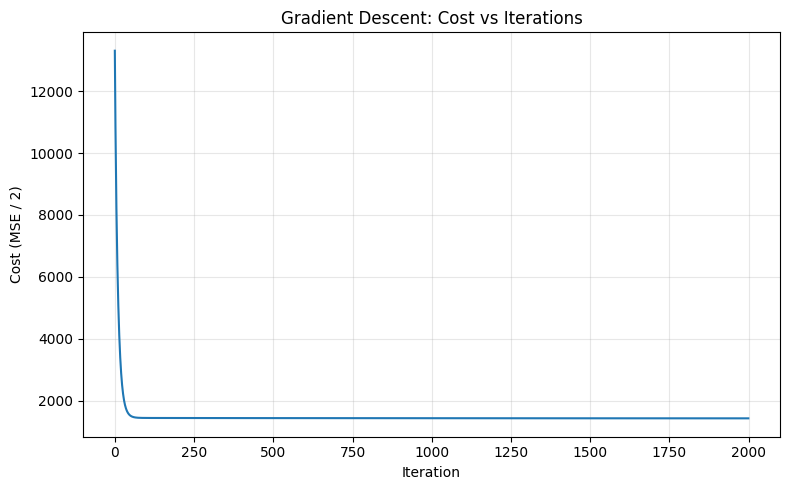

Initial cost: 13301.0171
Final cost  : 1436.757


In [9]:
plt.figure(figsize=(8, 5))
plt.plot(gd_cost_history)
plt.title("Gradient Descent: Cost vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost (MSE / 2)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Initial cost:", round(gd_cost_history[0], 4))
print("Final cost  :", round(gd_cost_history[-1], 4))

# **10. Evaluate the Gradient Descent Model**

Use the learned weights and bias to predict the test set. Calculate the same regression metrics used for the other models so that the results can be compared fairly.

In [10]:
gd_test_predictions = np.dot(X_test_scaled, gd_weights) + gd_bias

gd_mae = mean_absolute_error(y_test, gd_test_predictions)
gd_mse = mean_squared_error(y_test, gd_test_predictions)
gd_rmse = np.sqrt(gd_mse)
gd_r2 = r2_score(y_test, gd_test_predictions)

gd_results = pd.DataFrame([{
    "Model": "Linear Regression (Gradient Descent)",
    "MAE": gd_mae,
    "MSE": gd_mse,
    "RMSE": gd_rmse,
    "R2 Score": gd_r2
}])

display(gd_results.round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression (Gradient Descent),42.828,2889.923,53.758,0.455


# **11. Effect of Learning Rate**

Train Gradient Descent using different learning rates and compare the final cost. A learning rate that is too small may converge slowly, while a learning rate that is too large may cause unstable updates or divergence.

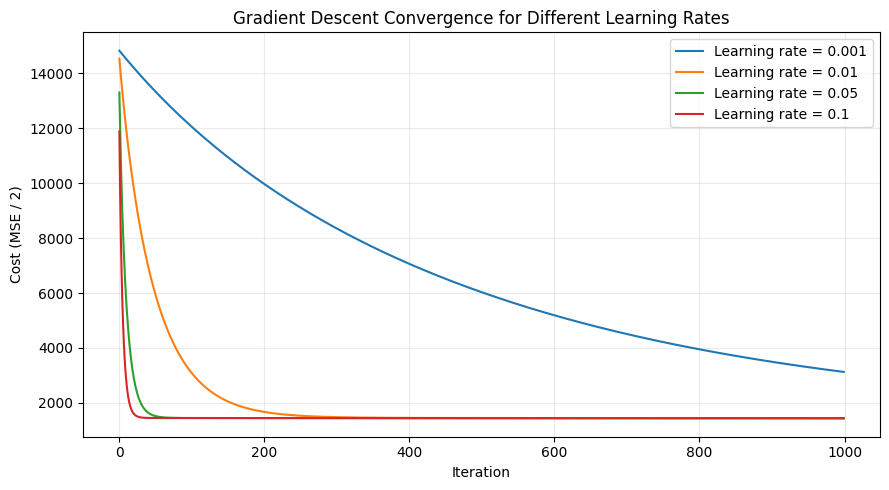

,Learning Rate,Final Cost
0,0.001,3127.2411
1,0.010,1447.3700
2,0.050,1440.5250
3,0.100,1436.7560


In [11]:
learning_rates = [0.001, 0.01, 0.05, 0.1]
learning_rate_results = []

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    _, _, history = gradient_descent(
        X_train_scaled, y_train.to_numpy(),
        learning_rate=lr, iterations=1000
    )
    learning_rate_results.append({
        "Learning Rate": lr,
        "Final Cost": history[-1]
    })
    plt.plot(history, label=f"Learning rate = {lr}")

plt.title("Gradient Descent Convergence for Different Learning Rates")
plt.xlabel("Iteration")
plt.ylabel("Cost (MSE / 2)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

lr_df = pd.DataFrame(learning_rate_results)
display(lr_df.round(4))

# **12. Compare Gradient Descent with Library Linear Regression**

Compare the Gradient Descent implementation with scikit-learn Linear Regression on the same scaled training and test data. Small differences may occur because of the optimization method and stopping conditions.

In [12]:
library_lr = LinearRegression()
library_lr.fit(X_train_scaled, y_train)

library_predictions = library_lr.predict(X_test_scaled)

comparison_metrics = pd.DataFrame([
    {
        "Model": "Gradient Descent",
        "MAE": mean_absolute_error(y_test, gd_test_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, gd_test_predictions)),
        "R2 Score": r2_score(y_test, gd_test_predictions)
    },
    {
        "Model": "Scikit-learn Linear Regression",
        "MAE": mean_absolute_error(y_test, library_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, library_predictions)),
        "R2 Score": r2_score(y_test, library_predictions)
    }
])

display(comparison_metrics.round(3))

,Model,MAE,RMSE,R2 Score
0,Gradient Descent,42.828,53.758,0.455
1,Scikit-learn Linear Regression,42.794,53.853,0.453


# **13. Result and Analysis**

Review the generated metric tables and plots before writing the final interpretation.

- The model with the lowest test RMSE has the smallest root mean squared prediction error among the tested models.
- A higher R² score indicates that the model explains more variation in the test target, but it does not guarantee that predictions are suitable for every use.
- MAE is easier to interpret as an average absolute error, while MSE penalizes large errors more strongly.
- Gradient Descent reduces the cost by repeatedly updating weights and bias. The convergence plot shows how quickly the selected learning rate reduces the cost.
- The learning-rate comparison demonstrates the trade-off between slow learning and unstable updates.
- Differences between Gradient Descent and scikit-learn Linear Regression can result from iteration limits and optimization details.

**Important:** Use the actual values displayed by your executed notebook when discussing which model performed best. Results are dependent on the dataset split and model settings.

# **14. Ethical Considerations and Limitations**

- The Diabetes dataset is intended for educational and research use; this model must not be used to diagnose, treat, or make decisions about an individual patient.
- Medical data can contain bias and may not represent every population equally.
- Predictions are estimates and can contain errors.
- The dataset is relatively small, so performance on other populations or future data may differ.
- Sensitive health information must be handled with privacy and security safeguards.
- A real clinical system would require domain-expert validation, larger representative datasets, fairness testing, and regulatory review.

# **Conclusion**

In this practical, multiple regression models were developed using the Diabetes dataset to predict a continuous measure of disease progression. Their performance was evaluated using MAE, MSE, RMSE, and R² score.

Linear Regression, Ridge Regression, Decision Tree, Random Forest, and Gradient Boosting were compared using the same test dataset. Gradient Descent was also implemented from scratch for Linear Regression. The cost-versus-iteration graph and learning-rate comparison helped explain the optimization process and its convergence behavior.

Thus, the experiment demonstrated how regression models can be developed, evaluated, and compared, and how Gradient Descent optimizes the parameters of Linear Regression.